# Importing data from Eyelink ASC files

This example shows how to read `.asc` files generated from Eyelink EDF files using `edf2asc`. Usually, it is easier to read the EDF file directly, see the [notebook on reading EDF files](importdata_edf.ipynb). However, the steps below show how to get data from any text-based format into `pypillometry`.

In [1]:
import os
import pypillometry as pp
from pypillometry import u
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In this example, we use data recorded with an Eyelink eyetracker. These eyetrackers store the data in binary files with the extension `.edf`. Some information about this file format is [here](http://download.sr-support.com/dispdoc/page25.html). We use a command-line utility released by Eyelink to convert this proprietary format into a more easily read `.asc` file that is a whitespace-separated plain-text format. The converter, `edf2asc`, can be downloaded for different platforms from the [Eyelink support forum](https://www.sr-research.com/support/). There is a GUI-based program for Windows and command-line programs for Linux and Mac. Binaries of the command-line tools for Linux and Mac are included in the `pypillometry` repository under [this link](https://github.com/ihrke/pypillometry/tree/master/external).

On Linux, we call the program twice on an example EDF file, once for the samples and once for the events:

In [2]:
!../../external/edf2asc-linux -y -s ../../data/test.edf ../../data/test_samples.asc
!../../external/edf2asc-linux -y -e ../../data/test.edf ../../data/test_events.asc


EDF2ASC: EyeLink EDF file -> ASCII (text) file translator
EDF2ASC version 3.0 Linux Dec  1 2008 
(c)1995-2007 by SR Research, last modified Dec  1 2008

processing file ../../data/test.edf 


=====================Preamble of file ../../data/test.edf======================
| DATE: Fri Feb 14 08:48:33 2020                                              |
| TYPE: EDF_FILE BINARY EVENT SAMPLE TAGGED                                   |
| VERSION: EYELINK II 1                                                       |
| SOURCE: EYELINK CL                                                          |
| EYELINK II CL v6.12 Feb  1 2018 (EyeLink Portable Duo)                      |
| CAMERA: EyeLink USBCAM Version 1.01                                         |
| SERIAL NUMBER: CLU-DAC49                                                    |
| CAMERA_CONFIG: DAC49200.SCD                                                 |
| Psychopy GC demo                                                            |



Processed [***      

Proc

Converted successfully: 0 events, 1245363 samples, 6 blocks.



EDF2ASC: EyeLink EDF file -> ASCII (text) file translator
EDF2ASC version 3.0 Linux Dec  1 2008 
(c)1995-2007 by SR Research, last modified Dec  1 2008

processing file ../../data/test.edf 


=====================Preamble of file ../../data/test.edf======================
| DATE: Fri Feb 14 08:48:33 2020                                              |
| TYPE: EDF_FILE BINARY EVENT SAMPLE TAGGED                                   |
| VERSION: EYELINK II 1                                                       |
| SOURCE: EYELINK CL                                                          |
| EYELINK II CL v6.12 Feb  1 2018 (EyeLink Portable Duo)                      |
| CAMERA: EyeLink USBCAM Version 1.01                                         |
| SERIAL NUMBER: CLU-DAC49                                                    |
| CAMERA_CONFIG: DAC49200.SCD                                                 |
| Psychopy GC demo                                                            |



Proc

Converted successfully: 37139 events, 0 samples, 6 blocks.


This results in two files, one containing all the samples and one all the recorded events.

In [3]:
fname_samples = "../../data/test_samples.asc"
fname_events = "../../data/test_events.asc"

The samples file contains a large table with the timestamp, x/y-coordinates of the eye position and pupil area for the left and the right eye (plus a column with status flags). Here are the first few rows of this file:

In [4]:
!head $fname_samples

3385900	  817.3	  345.2	 1707.0	  860.6	  375.2	 1738.0	.....
3385902	  817.0	  343.5	 1706.0	  860.7	  375.9	 1739.0	.....
3385904	  816.7	  341.6	 1705.0	  861.2	  376.6	 1739.0	.....
3385906	  816.7	  340.4	 1706.0	  861.7	  376.8	 1740.0	.....
3385908	  816.7	  340.2	 1707.0	  861.6	  376.9	 1742.0	.....
3385910	  816.8	  340.2	 1708.0	  861.1	  377.1	 1743.0	.....
3385912	  816.9	  340.9	 1708.0	  860.7	  377.5	 1744.0	.....
3385914	  816.1	  342.1	 1710.0	  861.1	  378.7	 1745.0	.....
3385916	  815.2	  343.2	 1712.0	  862.5	  380.0	 1746.0	.....
3385918	  814.4	  343.6	 1713.0	  863.9	  380.7	 1747.0	.....


We can read this file using `pandas.read_table()`. Eyelink marks missing x/y-coordinates with `"."` and missing pupil data with `0`. We convert both to `NaN`, which `pypillometry` treats as missing data. This is an explicit step: `pypillometry` does not interpret `0` as missing by itself.

In [5]:
df = pd.read_table(fname_samples,
                   names=["time", "left_x", "left_y", "left_p",
                          "right_x", "right_y", "right_p", "flags"],
                   na_values=".", skipinitialspace=True)

# Eyelink codes missing pupil data (e.g., blinks) as 0;
# set it to NaN so that pypillometry treats it as missing
df["left_p"] = df.left_p.replace(0, np.nan)
df["right_p"] = df.right_p.replace(0, np.nan)
df

,time,left_x,left_y,left_p,right_x,right_y,right_p,flags
0,3385900,817.3,345.2,1707.0,860.6,375.2,1738.0,.....
1,3385902,817.0,343.5,1706.0,860.7,375.9,1739.0,.....
2,3385904,816.7,341.6,1705.0,861.2,376.6,1739.0,.....
3,3385906,816.7,340.4,1706.0,861.7,376.8,1740.0,.....
4,3385908,816.7,340.2,1707.0,861.6,376.9,1742.0,.....
...,...,...,...,...,...,...,...,...
1245358,5923060,NaN,NaN,NaN,NaN,NaN,NaN,.C.C.
1245359,5923062,NaN,NaN,NaN,NaN,NaN,NaN,.C.C.
1245360,5923064,NaN,NaN,NaN,NaN,NaN,NaN,.C.C.
1245361,5923066,NaN,NaN,NaN,NaN,NaN,NaN,.C.C.


We can already use this information to create a `PupilData` object. We pass in the pupil area of both eyes (columns `left_p` and `right_p`) and the timestamps from the samples file. Gaps in the recording (where the eyetracker was paused) are filled with missing values:

pp: 12:34:06 | INFO     | fill_time_discontinuities:1774 | Filling in 5 gaps


pp: 12:34:06 | INFO     | fill_time_discontinuities:1776 | [32.35   4.012  6.21   2.02   1.862] seconds


PupilData(test, 48.4MiB):
 n               : 1268585
 sampling_rate   : 500.0
 eyes            : ['left', 'right']
 data            : ['left_pupil', 'right_pupil']
 nevents         : 0
 nblinks         : {}
 blinks          : {'left': None, 'right': None}
 duration_minutes: 42.28616666666667
 start_min       : 56.431666666666665
 end_min         : 98.7178
 params          : {}
 glimpse         : EyeDataDict(vars=2,n=1268585,shape=(1268585,)): 
  left_pupil (float64): 1707.0, 1706.0, 1705.0, 1706.0, 1707.0...
  right_pupil (float64): 1738.0, 1739.0, 1739.0, 1740.0, 1742.0...

 History:
 *
 └ fill_time_discontinuities()
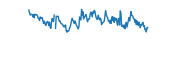
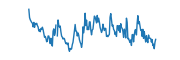

In [6]:
pp.PupilData(left_pupil=df.left_p, right_pupil=df.right_p, time=df.time, name="test")

We can also import the eye-tracking (gaze) data from the same file. In that case, we use the `EyeData` class:

pp: 12:34:06 | INFO     | fill_time_discontinuities:1774 | Filling in 5 gaps


pp: 12:34:06 | INFO     | fill_time_discontinuities:1776 | [32.35   4.012  6.21   2.02   1.862] seconds


EyeData(test, 125.8MiB):
 n                 : 1268585
 sampling_rate     : 500.0
 eyes              : ['left', 'right']
 data              : ['left_x', 'left_y', 'left_pupil', 'right_x', 'right_y', 'right_pupil']
 nevents           : 0
 experimental_setup: not set
 calibration       : not available
 duration_minutes  : 42.28616666666667
 start_min         : 56.431666666666665
 end_min           : 98.7178
 parameters        : {}
 glimpse           : EyeDataDict(vars=6,n=1268585,shape=(1268585,)): 
  left_x (float64): 817.3, 817.0, 816.7, 816.7, 816.7...
  left_y (float64): 345.2, 343.5, 341.6, 340.4, 340.2...
  left_pupil (float64): 1707.0, 1706.0, 1705.0, 1706.0, 1707.0...
  right_x (float64): 860.6, 860.7, 861.2, 861.7, 861.6...
  right_y (float64): 375.2, 375.9, 376.6, 376.8, 376.9...
  right_pupil (float64): 1738.0, 1739.0, 1739.0, 1740.0, 1742.0...

 nblinks           : {}
 blinks            : {'left': None, 'right': None}
 params            : {}
 History:
 *
 └ fill_time_discontinuities()
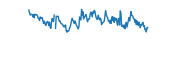
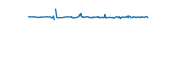
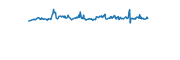
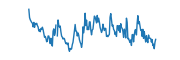
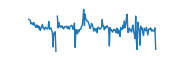
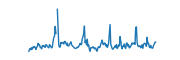

In [7]:
pp.EyeData(left_pupil=df.left_p, right_pupil=df.right_p,
           left_x=df.left_x, left_y=df.left_y,
           right_x=df.right_x, right_y=df.right_y,
           time=df.time, name="test")

This dataset is still missing the information contained in the events file which we need for analysing trial-related pupil data. The events file has a more complicated structure than the samples file:

In [8]:
!head -20 $fname_events

** CONVERTED FROM ../../data/test.edf using edfapi 3.0 Linux Dec  1 2008 on Wed Oct 28 12:34:05 2026
** DATE: Fri Feb 14 08:48:33 2020
** TYPE: EDF_FILE BINARY EVENT SAMPLE TAGGED
** VERSION: EYELINK II 1
** SOURCE: EYELINK CL
** EYELINK II CL v6.12 Feb  1 2018 (EyeLink Portable Duo)
** CAMERA: EyeLink USBCAM Version 1.01
** SERIAL NUMBER: CLU-DAC49
** CAMERA_CONFIG: DAC49200.SCD
** Psychopy GC demo
**

MSG	2728855 DISPLAY_COORDS = 0 0 1919 1079
INPUT	2767568	0
MSG	2784000 !CAL 
>>>>>>> CALIBRATION (HV9,P-CR) FOR LEFT: <<<<<<<<<
MSG	2784000 !CAL Calibration points:  
MSG	2784000 !CAL -29.4, -23.5        -0,     -2   
MSG	2784000 !CAL -29.3, -35.7        -0,  -1544   
MSG	2784000 !CAL -32.9, -10.4        -0,   1559   


After a header (lines starting with `**`) containing meta-information, we get a sequence of "events" which have different formats. We are interested in lines starting with "MSG" because those contain our experimental markers. Therefore, we read the events file and remove all rows that do not start with "MSG":

In [9]:
# read the whole file into variable `events` (list with one entry per line)
with open(fname_events) as f:
    events = f.readlines()

# keep only lines starting with "MSG"
events = [ev for ev in events if ev.startswith("MSG")]
events[0:10]

['MSG\t2728855 DISPLAY_COORDS = 0 0 1919 1079\n',
 'MSG\t2784000 !CAL \n',
 'MSG\t2784000 !CAL Calibration points:  \n',
 'MSG\t2784000 !CAL -29.4, -23.5        -0,     -2   \n',
 'MSG\t2784000 !CAL -29.3, -35.7        -0,  -1544   \n',
 'MSG\t2784000 !CAL -32.9, -10.4        -0,   1559   \n',
 'MSG\t2784000 !CAL -49.7, -23.0     -2835,     -2   \n',
 'MSG\t2784000 !CAL -10.8, -27.4      2835,     -2   \n',
 'MSG\t2784000 !CAL -48.3, -33.3     -2818,  -1544   \n',
 'MSG\t2784000 !CAL -11.0, -34.2      2818,  -1544   \n']

Our experiment sent a marker called `experiment_start` when the experiment started. Hence, we can remove all events before this marker.

In [10]:
experiment_start_index = np.where(["experiment_start" in ev for ev in events])[0][0]
events = events[experiment_start_index+1:]
events[0:10]

['MSG\t3387245 C_GW_1_1_UD_UD\n',
 'MSG\t3390421 F_GW_1_1_10_0\n',
 'MSG\t3392759 C_NW_1_2_UD_UD\n',
 'MSG\t3394293 R_NW_1_2_UD_UD\n',
 'MSG\t3395952 F_NW_1_2_-1_0\n',
 'MSG\t3397974 C_NA_1_3_UD_UD\n',
 'MSG\t3399892 R_NA_1_3_UD_UD\n',
 'MSG\t3400999 F_NA_1_3_-11_0\n',
 'MSG\t3403206 C_GA_1_4_UD_UD\n',
 'MSG\t3404640 R_GA_1_4_UD_UD\n']

Now we can convert the events into a `pandas.DataFrame` for further processing.

In [11]:
df_ev = pd.DataFrame([ev.split() for ev in events])
df_ev

,0,1,2,3,4,5,6,7,8
0,MSG,3387245,C_GW_1_1_UD_UD,NaN,NaN,NaN,NaN,NaN,NaN
1,MSG,3390421,F_GW_1_1_10_0,NaN,NaN,NaN,NaN,NaN,NaN
2,MSG,3392759,C_NW_1_2_UD_UD,NaN,NaN,NaN,NaN,NaN,NaN
3,MSG,3394293,R_NW_1_2_UD_UD,NaN,NaN,NaN,NaN,NaN,NaN
4,MSG,3395952,F_NW_1_2_-1_0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
1065,MSG,5893078,V_UD_UD_16_UD_UD,NaN,NaN,NaN,NaN,NaN,NaN
1066,MSG,5899076,V_UD_UD_17_UD_UD,NaN,NaN,NaN,NaN,NaN,NaN
1067,MSG,5905073,V_UD_UD_18_UD_UD,NaN,NaN,NaN,NaN,NaN,NaN
1068,MSG,5911072,V_UD_UD_19_UD_UD,NaN,NaN,NaN,NaN,NaN,NaN


In this table, the second column contains the timestamp (identical to the timestamp in the samples file), and the third column contains our custom markers (the format like "C_GW_1_1_UD_UD" is specific to our experimental design). There are more columns which seem to contain no information for most rows. Let's check what those columns are for by printing the rows where the fifth column is not empty:

In [12]:
df_ev[df_ev[4].notna()].head()

,0,1,2,3,4,5,6,7,8
209,MSG,3900393,RECCFG,CR,500,2,1,LR,NaN
211,MSG,3900393,GAZE_COORDS,0.00,0.00,1919.00,1079.00,NaN,NaN
212,MSG,3900393,THRESHOLDS,L,56,231,R,66,239
213,MSG,3900393,ELCL_WINDOW_SIZES,176,188,0,0,NaN,NaN
215,MSG,3900393,ELCL_PROC,CENTROID,(3),NaN,NaN,NaN,NaN


Apparently, there are more eyetracker-specific markers in our files (in this case due to drift checks during the experiment). We can drop those by removing all rows in which the fifth column is not empty and then dropping all other columns.

In [13]:
df_ev = df_ev[df_ev[4].isna()][[1, 2]]
df_ev.columns = ["time", "event"]
df_ev

,time,event
0,3387245,C_GW_1_1_UD_UD
1,3390421,F_GW_1_1_10_0
2,3392759,C_NW_1_2_UD_UD
3,3394293,R_NW_1_2_UD_UD
4,3395952,F_NW_1_2_-1_0
...,...,...
1065,5893078,V_UD_UD_16_UD_UD
1066,5899076,V_UD_UD_17_UD_UD
1067,5905073,V_UD_UD_18_UD_UD
1068,5911072,V_UD_UD_19_UD_UD


Finally, we can pass the event markers to our `PupilData`, `EyeData` or `GazeData` object.

pp: 12:34:08 | INFO     | fill_time_discontinuities:1774 | Filling in 5 gaps


pp: 12:34:08 | INFO     | fill_time_discontinuities:1776 | [32.35   4.012  6.21   2.02   1.862] seconds


PupilData(test, 48.4MiB):
 n               : 1268585
 sampling_rate   : 500.0
 eyes            : ['left', 'right']
 data            : ['left_pupil', 'right_pupil']
 nevents         : 1035
 nblinks         : {}
 blinks          : {'left': None, 'right': None}
 duration_minutes: 42.28616666666667
 start_min       : 56.431666666666665
 end_min         : 98.7178
 params          : {}
 glimpse         : EyeDataDict(vars=2,n=1268585,shape=(1268585,)): 
  left_pupil (float64): 1707.0, 1706.0, 1705.0, 1706.0, 1707.0...
  right_pupil (float64): 1738.0, 1739.0, 1739.0, 1740.0, 1742.0...

 History:
 *
 └ fill_time_discontinuities()
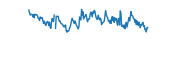
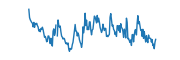

In [14]:
d = pp.PupilData(left_pupil=df.left_p, right_pupil=df.right_p, time=df.time,
                 event_onsets=df_ev.time.astype(float), event_labels=df_ev.event,
                 name="test")
d

The summary shows that the eyetracker started recording at time 56.4 minutes. We can let the time start at 0 by using `reset_time()`:

In [15]:
d = d.reset_time()

Now we can use all `pypillometry` functions on this dataset, e.g., plot a minute of the data. Missing (NaN) samples are masked automatically and highlighted in red. See the [blinks notebook](blinks.ipynb) for how to detect and interpolate blinks.

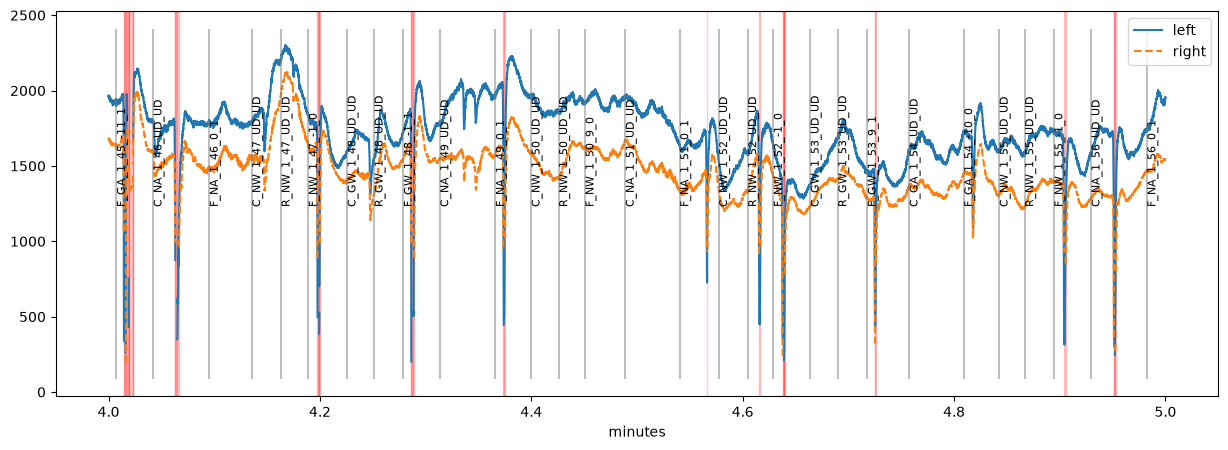

In [16]:
plt.figure(figsize=(15, 5))
d.plot.pupil_plot(plot_range=(4, 5) * u.min, units="min")

## Generalize to multiple similar datasets

Now that we have found a way to create our `EyeData` object from the raw files, we can wrap the code from this notebook into a function that creates such objects for any file with the same structure.

NOTE: You may want to consider using a [configuration file to facilitate loading and sharing your study data](../user_guide/studies.rst).

The function takes the name of an EDF file as input, runs all the code above and returns the final `EyeData` object. For convenience, we assume that `edf2asc` has already been run so that the `.asc` files are available (see above).

In [17]:
datapath = "../../data"  # this is where the data files are located

def read_dataset(edffile):
    basename = os.path.splitext(edffile)[0]  # remove .edf from filename
    fname_samples = os.path.join(datapath, basename+"_samples.asc")
    fname_events = os.path.join(datapath, basename+"_events.asc")
    print("> Loading '%s' and '%s'" % (fname_samples, fname_events))

    # read samples file
    df = pd.read_table(fname_samples,
                       names=["time", "left_x", "left_y", "left_p",
                              "right_x", "right_y", "right_p", "flags"],
                       na_values=".", skipinitialspace=True)
    df["left_p"] = df.left_p.replace(0, np.nan)
    df["right_p"] = df.right_p.replace(0, np.nan)

    # read events file, keep only messages after the experiment started
    with open(fname_events) as f:
        events = [ev for ev in f.readlines() if ev.startswith("MSG")]
    experiment_start_index = np.where(["experiment_start" in ev for ev in events])[0][0]
    events = events[experiment_start_index+1:]
    df_ev = pd.DataFrame([ev.split() for ev in events])
    df_ev = df_ev[df_ev[4].isna()][[1, 2]]
    df_ev.columns = ["time", "event"]

    # create EyeData object
    d = pp.EyeData(left_pupil=df.left_p, right_pupil=df.right_p,
                   left_x=df.left_x, left_y=df.left_y,
                   right_x=df.right_x, right_y=df.right_y,
                   time=df.time,
                   event_onsets=df_ev.time.astype(float), event_labels=df_ev.event,
                   name=basename)
    return d.reset_time()

We can test this code by running the function with a filename located in `datapath`:

In [18]:
d = read_dataset("test.edf")

> Loading '../../data/test_samples.asc' and '../../data/test_events.asc'


pp: 12:34:11 | INFO     | fill_time_discontinuities:1774 | Filling in 5 gaps


pp: 12:34:11 | INFO     | fill_time_discontinuities:1776 | [32.35   4.012  6.21   2.02   1.862] seconds


After that, we might want to save the final `EyeData` object to a file that can be loaded back quickly. This can be done using `EyeData.write_file()` or `pp.write_pickle()`:

In [19]:
os.makedirs("example_data", exist_ok=True)
fname = os.path.join("example_data", d.name+".pd")
print(fname)
d.write_file(fname)

example_data/test.pd


The dataset can be read back using `EyeData.from_file()`:

EyeData(test, 125.8MiB):
 n                 : 1268585
 sampling_rate     : 500.0
 eyes              : ['left', 'right']
 data              : ['left_x', 'left_y', 'left_pupil', 'right_x', 'right_y', 'right_pupil']
 nevents           : 1035
 experimental_setup: not set
 calibration       : not available
 duration_minutes  : 42.28616666666667
 start_min         : 0.0
 end_min           : 42.28613333333333
 parameters        : {}
 glimpse           : EyeDataDict(vars=6,n=1268585,shape=(1268585,)): 
  left_x (float64): 817.3, 817.0, 816.7, 816.7, 816.7...
  left_y (float64): 345.2, 343.5, 341.6, 340.4, 340.2...
  left_pupil (float64): 1707.0, 1706.0, 1705.0, 1706.0, 1707.0...
  right_x (float64): 860.6, 860.7, 861.2, 861.7, 861.6...
  right_y (float64): 375.2, 375.9, 376.6, 376.8, 376.9...
  right_pupil (float64): 1738.0, 1739.0, 1739.0, 1740.0, 1742.0...

 nblinks           : {}
 blinks            : {'left': None, 'right': None}
 params            : {}
 History:
 *
 └ fill_time_discontinuities()
  └ reset_time()
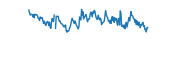
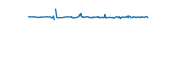
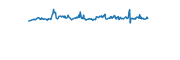
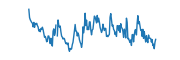
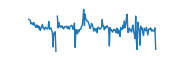
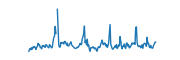

In [20]:
d2 = pp.EyeData.from_file(fname)
d2